In [24]:
import os
import pandas as pd
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

data_path = Path("/kaggle/input/datasets/mahmoudreda55/satellite-image-classification/data")

print(os.listdir(data_path))

['cloudy', 'desert', 'green_area', 'water']


In [25]:
images = []
labels = []

for category in os.listdir(data_path):
    folder = data_path / category

    if folder.is_dir():
        for file in folder.glob("*.jpg"):
            images.append(str(file))
            labels.append(category)

df = pd.DataFrame({
    "path": images,
    "label": labels
})

In [26]:
print(df.shape)

(5631, 2)


In [27]:
print(df["label"].value_counts())

label
cloudy        1500
green_area    1500
water         1500
desert        1131
Name: count, dtype: int64


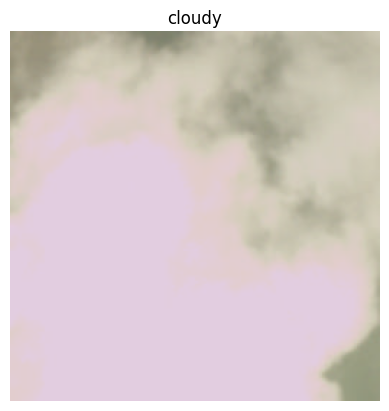

In [28]:
image = Image.open(df.iloc[0]["path"])

plt.imshow(image)
plt.title(df.iloc[0]["label"])
plt.axis("off")
plt.show()

## Detect and remove duplicates
We can use SHA-256 hashing to identify images with identical decoded pixel data, even if their filenames differ.

In [29]:
from pathlib import Path
import hashlib

def image_hash(path):
    with Image.open(path) as img:
        img = img.convert("RGB")
        h = hashlib.sha256()
        h.update(str(img.size).encode())
        h.update(img.tobytes())
        return h.hexdigest()

df["hash"] = df["path"].apply(image_hash)

duplicates = df[df.duplicated(
    subset="hash",
    keep=False
)]

print("Duplicate image records:", len(duplicates))
print("Extra duplicate copies:", df.duplicated("hash").sum())

display(duplicates.sort_values("hash").head(20))

Duplicate image records: 78
Extra duplicate copies: 39


,path,label,hash
2385,/kaggle/input/datasets/mahmoudreda55/satellite...,desert,039a6a6a9eca9fc558043dea4ed7f266b5d1da0ddb2bcf...
2384,/kaggle/input/datasets/mahmoudreda55/satellite...,desert,039a6a6a9eca9fc558043dea4ed7f266b5d1da0ddb2bcf...
2206,/kaggle/input/datasets/mahmoudreda55/satellite...,desert,0d57fa3122f6e7e3d20c42dacbe607376b6d193dd28377...
2205,/kaggle/input/datasets/mahmoudreda55/satellite...,desert,0d57fa3122f6e7e3d20c42dacbe607376b6d193dd28377...
2342,/kaggle/input/datasets/mahmoudreda55/satellite...,desert,10a96767c6f42d095e5ab3ea305c67979c5b2b4bb71f12...
2343,/kaggle/input/datasets/mahmoudreda55/satellite...,desert,10a96767c6f42d095e5ab3ea305c67979c5b2b4bb71f12...
2341,/kaggle/input/datasets/mahmoudreda55/satellite...,desert,1162e1b91250bbc1f82959e53fd28c195f8b7a476ded8f...
2340,/kaggle/input/datasets/mahmoudreda55/satellite...,desert,1162e1b91250bbc1f82959e53fd28c195f8b7a476ded8f...
1954,/kaggle/input/datasets/mahmoudreda55/satellite...,desert,175735f9142ed0e8b684d78d677f70fffbfa0be9830c90...
1955,/kaggle/input/datasets/mahmoudreda55/satellite...,desert,175735f9142ed0e8b684d78d677f70fffbfa0be9830c90...


Original images	5,631

Extra duplicate copies	39

Expected images after removal	5,592

In [30]:
conflicts = df.groupby("hash")["label"].nunique()

conflicting_hashes = conflicts[conflicts > 1]

print("Conflicting label groups:", len(conflicting_hashes))

Conflicting label groups: 0


In [31]:
df_clean = df.drop_duplicates(
    subset="hash",
    keep="first"
).reset_index(drop=True)

print("Before:", len(df))
print("After:", len(df_clean))
print("Removed:", len(df) - len(df_clean))

Before: 5631
After: 5592
Removed: 39


## Split the dataset
70% train / 15% validation / 15% test, stratified, using the cleaned data (no duplicates).

In [32]:
from sklearn.model_selection import train_test_split

# first take 70% for training, the other 30% is split in half
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    random_state=42,
    stratify=df_clean["label"]
)

# half of the 30% -> validation, the other half -> test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 3914
Validation: 839
Testing: 839


## Standardize image dimensions

In [33]:
def resize_images(dataframe):
    images = []
    labels = []

    for _, row in dataframe.iterrows():
        with Image.open(row["path"]) as img:
            img = img.convert("RGB")
            img = img.resize(
                (64, 64),
                Image.Resampling.LANCZOS
            )
            images.append(np.array(img))
            labels.append(row["label"])

    return np.array(images), np.array(labels)

X_train, y_train = resize_images(train_df)
X_val, y_val = resize_images(val_df)
X_test, y_test = resize_images(test_df)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

Training shape: (3914, 64, 64, 3)
Validation shape: (839, 64, 64, 3)
Testing shape: (839, 64, 64, 3)


## Normalize pixel values

In [34]:
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Min:", X_train.min())
print("Max:", X_train.max())
print("Shape:", X_train.shape)

Min: 0.023529412
Max: 1.0
Shape: (3914, 64, 64, 3)


## Flatten the images
Logistic Regression and KNN expect 2D data, but the images are currently 4D.

In [35]:
# Flatten images into 2D arrays

X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_val_flat = X_val.reshape(X_val.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

print("Training shape:", X_train_flat.shape)
print("Validation shape:", X_val_flat.shape)
print("Testing shape:", X_test_flat.shape)

Training shape: (3914, 12288)
Validation shape: (839, 12288)
Testing shape: (839, 12288)


In [36]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y_train_encoded = encoder.fit_transform(y_train)
y_val_encoded = encoder.transform(y_val)
y_test_encoded = encoder.transform(y_test)

print("Classes:", encoder.classes_)

Classes: ['cloudy' 'desert' 'green_area' 'water']


## Feature extraction
Scale the pixels, reduce them with PCA, and add color histograms (they help a lot to tell water from green areas).
The scaler and PCA are fitted on the training data only.

In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# scale pixels (fit on train only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_flat)
X_val_scaled = scaler.transform(X_val_flat)
X_test_scaled = scaler.transform(X_test_flat)

# PCA (fit on train only)
pca = PCA(n_components=100, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original:", X_train_flat.shape)
print("After PCA:", X_train_pca.shape)
print("Variance retained:", pca.explained_variance_ratio_.sum())

Original: (3914, 12288)
After PCA: (3914, 100)
Variance retained: 0.99592173


In [38]:
# color histogram: 16 bins for each of the R, G, B channels
def color_hist(images, bins=16):
    feats = []
    for img in images:
        h = [np.histogram(img[:, :, c], bins=bins, range=(0, 1))[0] for c in range(3)]
        feats.append(np.concatenate(h) / (img.shape[0] * img.shape[1]))
    return np.array(feats)

X_train_feat = np.hstack([X_train_pca, color_hist(X_train)])
X_val_feat = np.hstack([X_val_pca, color_hist(X_val)])
X_test_feat = np.hstack([X_test_pca, color_hist(X_test)])

# scale the combined features so PCA and histogram values are on the same level
final_scaler = StandardScaler()
X_train_final = final_scaler.fit_transform(X_train_feat)
X_val_final = final_scaler.transform(X_val_feat)
X_test_final = final_scaler.transform(X_test_feat)

print("Final feature shape:", X_train_final.shape)

Final feature shape: (3914, 148)


## Tune the models on the validation set

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# try different C values, pick the best one on the validation set
best_C, best_val = None, 0

for C in [0.01, 0.1, 1, 10, 100]:
    model = LogisticRegression(C=C, max_iter=2000, random_state=42)
    model.fit(X_train_final, y_train_encoded)
    acc = accuracy_score(y_val_encoded, model.predict(X_val_final))
    print(f"C = {C:<6} validation accuracy = {acc:.4f}")
    if acc > best_val:
        best_C, best_val = C, acc

print("Best C:", best_C)

logistic_model = LogisticRegression(C=best_C, max_iter=2000, random_state=42)
logistic_model.fit(X_train_final, y_train_encoded)

C = 0.01   validation accuracy = 0.9094
C = 0.1    validation accuracy = 0.9118
C = 1      validation accuracy = 0.9178
C = 10     validation accuracy = 0.9154
C = 100    validation accuracy = 0.9106
Best C: 1


LogisticRegression(C=1, max_iter=2000, random_state=42)

In [40]:
from sklearn.neighbors import KNeighborsClassifier

# try different k values, pick the best one on the validation set
best_k, best_val = None, 0

for k in [1, 3, 5, 7, 9, 11, 15, 21]:
    model = KNeighborsClassifier(n_neighbors=k, weights="distance", n_jobs=-1)
    model.fit(X_train_final, y_train_encoded)
    acc = accuracy_score(y_val_encoded, model.predict(X_val_final))
    print(f"k = {k:<3} validation accuracy = {acc:.4f}")
    if acc > best_val:
        best_k, best_val = k, acc

print("Best k:", best_k)

knn_model = KNeighborsClassifier(n_neighbors=best_k, weights="distance", n_jobs=-1)
knn_model.fit(X_train_final, y_train_encoded)

k = 1   validation accuracy = 0.8188
k = 3   validation accuracy = 0.8248
k = 5   validation accuracy = 0.8260
k = 7   validation accuracy = 0.8296
k = 9   validation accuracy = 0.8200
k = 11  validation accuracy = 0.8188
k = 15  validation accuracy = 0.8117
k = 21  validation accuracy = 0.8057
Best k: 7


KNeighborsClassifier(n_jobs=-1, n_neighbors=7, weights='distance')

## K-Means (unsupervised)
K-Means never sees the labels while it learns: it only groups similar images into 4 clusters.
Logistic Regression and KNN are supervised, they learn from the labels.
To get an accuracy, each cluster is mapped to the most frequent true label inside it (using the training data).

In [41]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
train_clusters = kmeans.fit_predict(X_train_final)

# map each cluster to its most frequent true label
cluster_to_label = {}
for c in range(4):
    cluster_to_label[c] = np.bincount(y_train_encoded[train_clusters == c]).argmax()

print("Cluster -> label:", {c: encoder.classes_[l] for c, l in cluster_to_label.items()})

val_clusters = kmeans.predict(X_val_final)
kmeans_val_pred = np.array([cluster_to_label[c] for c in val_clusters])
print("K-Means validation accuracy:", accuracy_score(y_val_encoded, kmeans_val_pred))

# silhouette score (sample to keep it fast)
sil_score = silhouette_score(X_train_final, train_clusters, sample_size=2000, random_state=42)
print("Silhouette score:", sil_score)

Cluster -> label: {0: np.str_('cloudy'), 1: np.str_('cloudy'), 2: np.str_('cloudy'), 3: np.str_('green_area')}
K-Means validation accuracy: 0.5268176400476758
Silhouette score: 0.10281418858439362


## Final evaluation on the test set
The test set is used only here, once, after all the tuning is finished.

In [42]:
from sklearn.metrics import classification_report, f1_score

logistic_pred = logistic_model.predict(X_test_final)
knn_pred = knn_model.predict(X_test_final)
kmeans_pred = np.array([cluster_to_label[c] for c in kmeans.predict(X_test_final)])

for name, pred in [("LOGISTIC REGRESSION", logistic_pred),
                   ("KNN", knn_pred),
                   ("K-MEANS (mapped clusters)", kmeans_pred)]:
    print(name)
    print("Accuracy:", accuracy_score(y_test_encoded, pred))
    print(classification_report(y_test_encoded, pred, target_names=encoder.classes_))
    print()

LOGISTIC REGRESSION
Accuracy: 0.9177592371871275
              precision    recall  f1-score   support

      cloudy       0.98      0.91      0.94       225
      desert       0.92      0.98      0.95       164
  green_area       0.87      0.93      0.90       225
       water       0.91      0.87      0.89       225

    accuracy                           0.92       839
   macro avg       0.92      0.92      0.92       839
weighted avg       0.92      0.92      0.92       839


KNN
Accuracy: 0.8259833134684148
              precision    recall  f1-score   support

      cloudy       0.96      0.90      0.93       225
      desert       0.95      0.97      0.96       164
  green_area       0.80      0.58      0.68       225
       water       0.67      0.89      0.77       225

    accuracy                           0.83       839
   macro avg       0.85      0.84      0.83       839
weighted avg       0.84      0.83      0.82       839


K-MEANS (mapped clusters)
Accuracy: 0.53158522

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


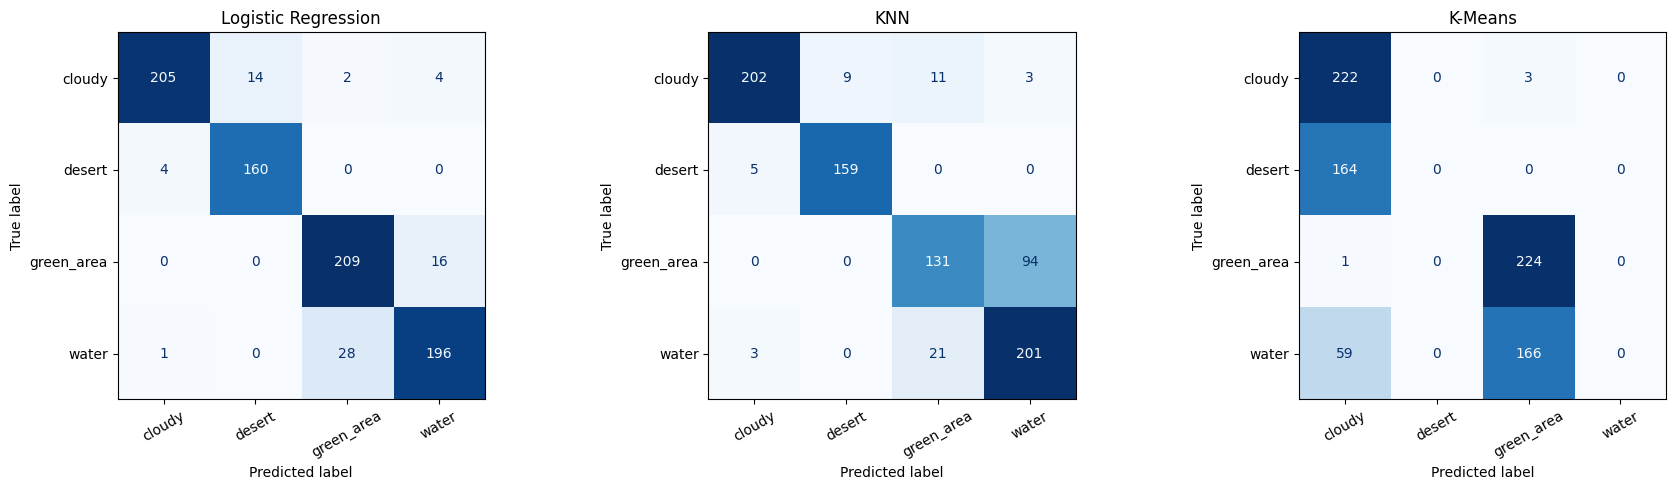

In [43]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, name, pred in zip(axes,
                          ["Logistic Regression", "KNN", "K-Means"],
                          [logistic_pred, knn_pred, kmeans_pred]):
    ConfusionMatrixDisplay.from_predictions(
        y_test_encoded, pred,
        display_labels=encoder.classes_,
        ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

,Model,Accuracy,F1 Score (Macro)
0,Logistic Regression,0.917759,0.919756
1,KNN,0.825983,0.832617
2,K-Means,0.531585,0.346655


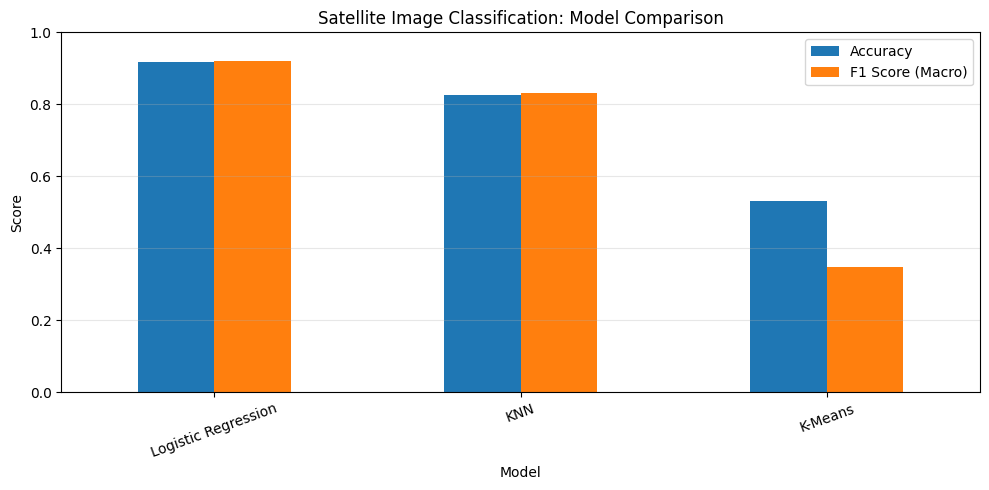

In [44]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN", "K-Means"],
    "Accuracy": [
        accuracy_score(y_test_encoded, logistic_pred),
        accuracy_score(y_test_encoded, knn_pred),
        accuracy_score(y_test_encoded, kmeans_pred)
    ],
    "F1 Score (Macro)": [
        f1_score(y_test_encoded, logistic_pred, average="macro"),
        f1_score(y_test_encoded, knn_pred, average="macro"),
        f1_score(y_test_encoded, kmeans_pred, average="macro")
    ]
})

display(results.sort_values("Accuracy", ascending=False))

results.plot(
    x="Model",
    y=["Accuracy", "F1 Score (Macro)"],
    kind="bar",
    figsize=(10, 5),
    rot=20
)

plt.title("Satellite Image Classification: Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

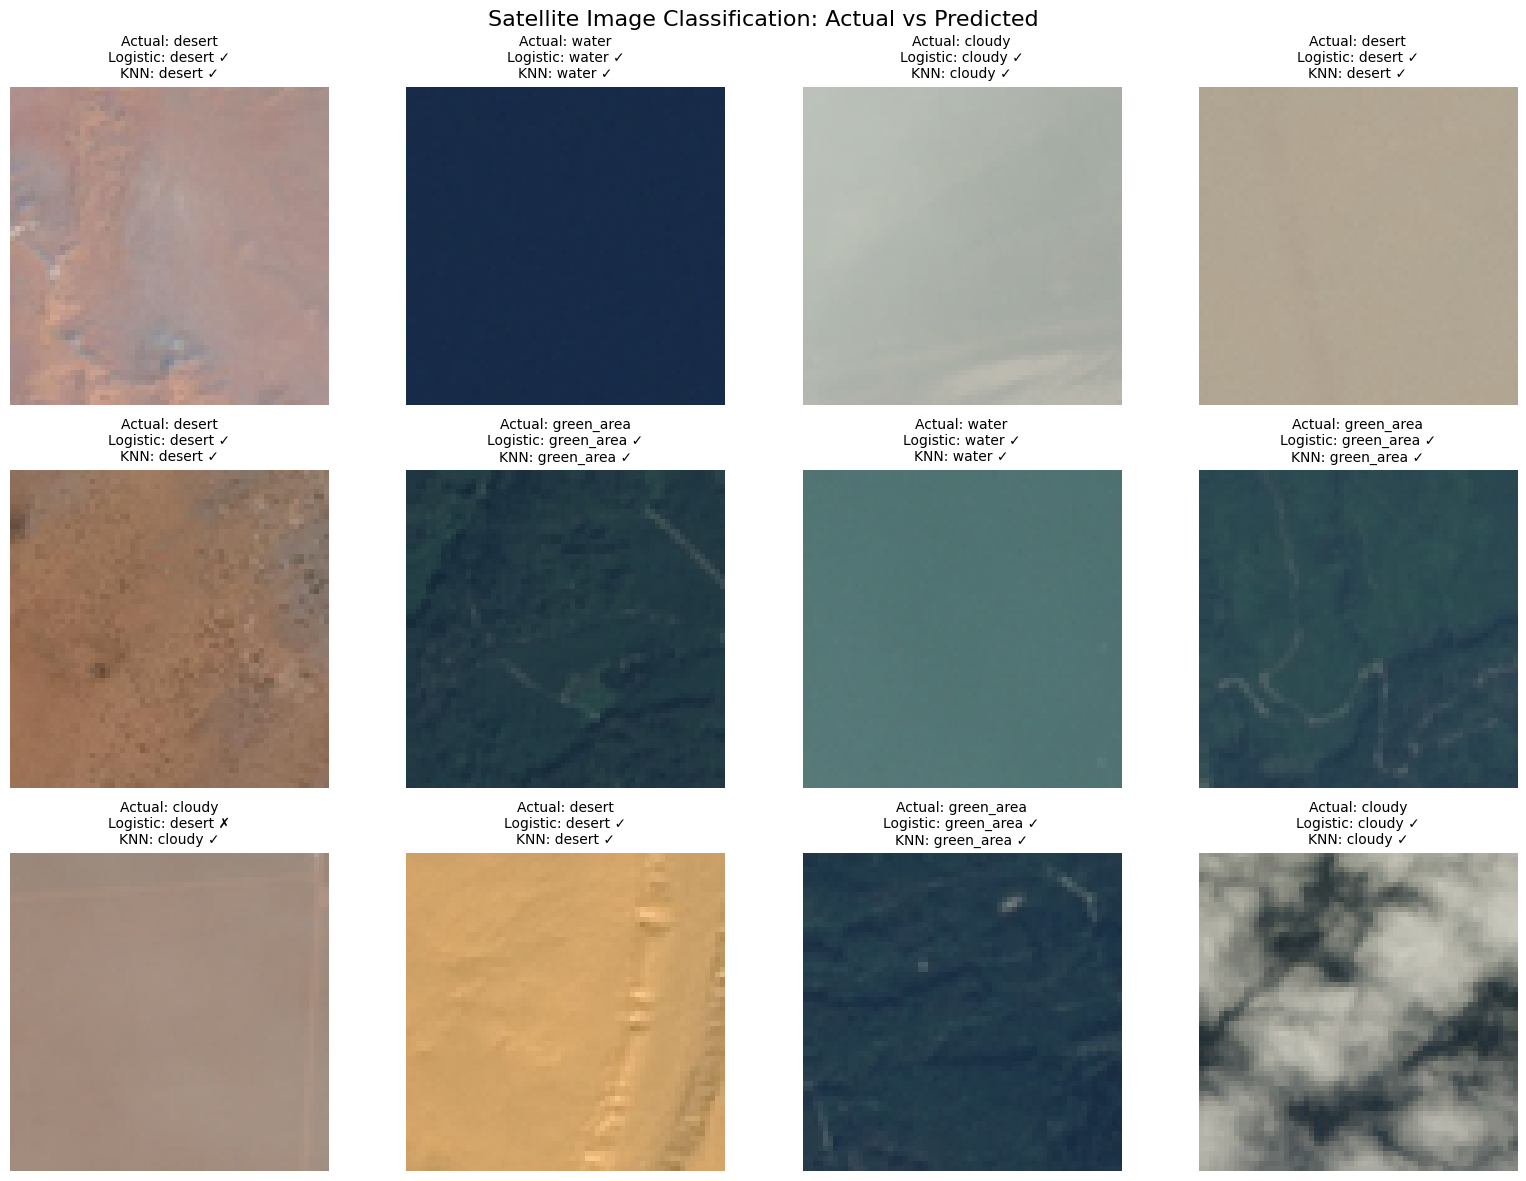

In [45]:
# Select 12 random test images
rng = np.random.default_rng(42)
indices = rng.choice(len(X_test), size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for ax, i in zip(axes.flat, indices):

    # Original normalized image (not PCA features)
    image = X_test[i]

    actual = encoder.inverse_transform([y_test_encoded[i]])[0]
    logistic_label = encoder.inverse_transform([logistic_pred[i]])[0]
    knn_label = encoder.inverse_transform([knn_pred[i]])[0]

    ax.imshow(image)

    # Show predictions from both models
    ax.set_title(
        f"Actual: {actual}\n"
        f"Logistic: {logistic_label} "
        f"{'✓' if actual == logistic_label else '✗'}\n"
        f"KNN: {knn_label} "
        f"{'✓' if actual == knn_label else '✗'}",
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "Satellite Image Classification: Actual vs Predicted",
    fontsize=16
)
plt.tight_layout()
plt.show()

## Save everything for the GUI
The GUI must repeat the same steps: resize to 64x64, divide by 255, flatten, scaler, PCA, color_hist, final_scaler, then the model.

In [46]:
import joblib

os.makedirs("saved_models", exist_ok=True)

joblib.dump(encoder, "saved_models/label_encoder.joblib")
joblib.dump(scaler, "saved_models/scaler.joblib")
joblib.dump(pca, "saved_models/pca.joblib")
joblib.dump(final_scaler, "saved_models/final_scaler.joblib")
joblib.dump(logistic_model, "saved_models/logistic_model.joblib")
joblib.dump(knn_model, "saved_models/knn_model.joblib")
joblib.dump(kmeans, "saved_models/kmeans_model.joblib")
joblib.dump(cluster_to_label, "saved_models/cluster_to_label.joblib")

print(os.listdir("saved_models"))

['logistic_model.joblib', 'kmeans_model.joblib', 'knn_model.joblib', 'scaler.joblib', 'label_encoder.joblib', 'final_scaler.joblib', 'pca.joblib', 'cluster_to_label.joblib']
